In [3]:
import pandas as pd
import requests

print("Anomark notebook is working!")
print("Pandas version:", pd.__version__)

Anomark notebook is working!
Pandas version: 3.1.0


In [5]:
import requests
import pandas as pd

url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

params = {
    "$limit": 10000,
    "$select": "unique_key,created_date,closed_date,agency,complaint_type,borough,status,incident_zip",
    "$where": "created_date >= '2025-01-01T00:00:00' AND created_date < '2025-02-01T00:00:00'"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

records = response.json()
df = pd.DataFrame(records)

print("Records fetched:", len(df))

Records fetched: 10000


In [12]:
df.shape

(10000, 8)

In [6]:
df.head()

,unique_key,created_date,closed_date,agency,complaint_type,borough,status,incident_zip
0,63950044,2025-01-31T23:59:48.000,2025-02-01T04:44:27.000,NYPD,Noise - Street/Sidewalk,MANHATTAN,Closed,10033
1,63945541,2025-01-31T23:59:45.000,2025-02-01T17:35:57.000,HPD,HEAT/HOT WATER,BROOKLYN,Closed,11230
2,63947478,2025-01-31T23:59:19.000,2025-02-01T10:33:54.000,NYPD,Blocked Driveway,BROOKLYN,Closed,11229
3,63950000,2025-01-31T23:59:00.000,2025-02-03T23:00:00.000,DEP,Noise,BRONX,Closed,10459
4,63948032,2025-01-31T23:59:00.000,2025-02-01T06:55:00.000,DOT,Traffic Signal Condition,MANHATTAN,Closed,10004


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   unique_key      10000 non-null  str  
 1   created_date    10000 non-null  str  
 2   closed_date     9934 non-null   str  
 3   agency          10000 non-null  str  
 4   complaint_type  10000 non-null  str  
 5   borough         10000 non-null  str  
 6   status          10000 non-null  str  
 7   incident_zip    9905 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [8]:
print("column names:",df.columns.tolist())

column names: ['unique_key', 'created_date', 'closed_date', 'agency', 'complaint_type', 'borough', 'status', 'incident_zip']


In [13]:
display(df.describe(include="all").T)

,count,unique,top,freq
unique_key,10000,10000,63950044,1
created_date,10000,8154,2025-01-31T10:38:00.000,14
closed_date,9934,7703,2025-02-02T13:30:25.000,57
agency,10000,13,NYPD,4263
complaint_type,10000,122,Illegal Parking,1740
borough,10000,6,BROOKLYN,3130
status,10000,6,Closed,9945
incident_zip,9905,189,11226,185


In [14]:
# Convert dates to datetime for analysis
for col in ["created_date", "closed_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Earliest request:", df["created_date"].min())
print("Latest request:", df["created_date"].max())

print("\nData types:")
print(df.dtypes)

print("\nUnique request IDs:", df["unique_key"].nunique())
print("Total rows:", len(df))

Earliest request: 2025-01-30 20:45:56
Latest request: 2025-01-31 23:59:48

Data types:
unique_key                   str
created_date      datetime64[us]
closed_date       datetime64[us]
agency                       str
complaint_type               str
borough                      str
status                       str
incident_zip                 str
dtype: object

Unique request IDs: 10000
Total rows: 10000


,Missing Count,Missing Percentage
incident_zip,95,0.95
closed_date,66,0.66
created_date,0,0.00
unique_key,0,0.00
agency,0,0.00
complaint_type,0,0.00
borough,0,0.00
status,0,0.00


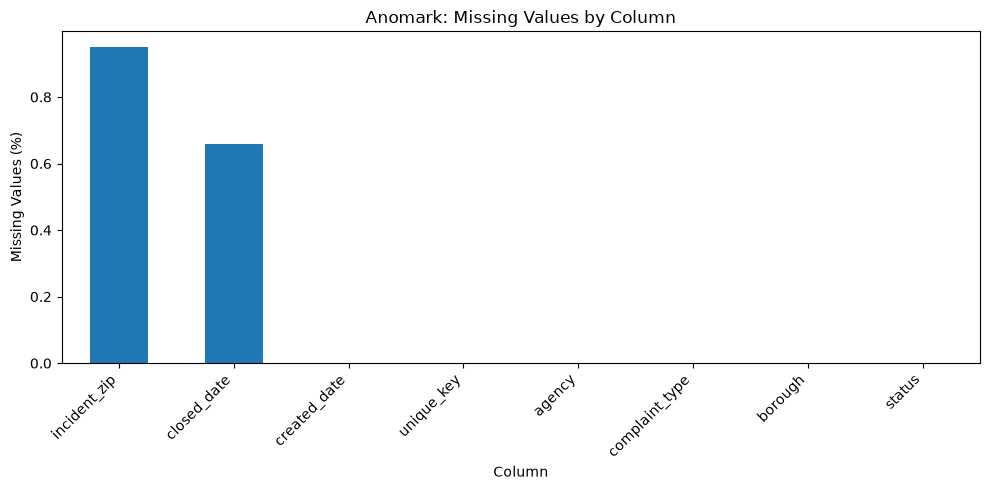

In [19]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Missing Percentage", ascending=False))

# Visualize missing percentages
import matplotlib.pyplot as plt

missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)

missing_pct.plot(kind="bar", figsize=(10, 5))
plt.title("Anomark: Missing Values by Column")
plt.ylabel("Missing Values (%)")
plt.xlabel("Column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [20]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate request IDs:", df["unique_key"].duplicated().sum())
print("Unique request IDs:", df["unique_key"].nunique())

# Inspect any repeated IDs
duplicate_ids = df[df["unique_key"].duplicated(keep=False)].sort_values("unique_key")

display(duplicate_ids.head(20))

Fully duplicated rows: 0
Duplicate request IDs: 0
Unique request IDs: 10000


,unique_key,created_date,closed_date,agency,complaint_type,borough,status,incident_zip


In [21]:
categorical_cols = ["agency", "complaint_type", "borough", "status"]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).head(15).to_frame("Count"))


--- agency ---


,Count
agency,
NYPD,4263
HPD,2672
DSNY,901
DOT,809
DEP,468
DOB,276
DOHMH,239
DPR,132
TLC,94



--- complaint_type ---


,Count
complaint_type,
Illegal Parking,1740
HEAT/HOT WATER,1232
Noise - Residential,977
Blocked Driveway,560
Traffic Signal Condition,396
UNSANITARY CONDITION,337
PLUMBING,244
Noise - Commercial,216
Abandoned Vehicle,216



--- borough ---


,Count
borough,
BROOKLYN,3130
QUEENS,2347
MANHATTAN,2190
BRONX,1979
STATEN ISLAND,343
Unspecified,11



--- status ---


,Count
status,
Closed,9945
In Progress,32
Assigned,9
Open,6
Pending,6
Started,2


,date,request_count
0,2025-01-30,1181
1,2025-01-31,8819


,request_count
count,2.000000
mean,5000.000000
std,5400.881595
min,1181.000000
25%,3090.500000
50%,5000.000000
75%,6909.500000
max,8819.000000


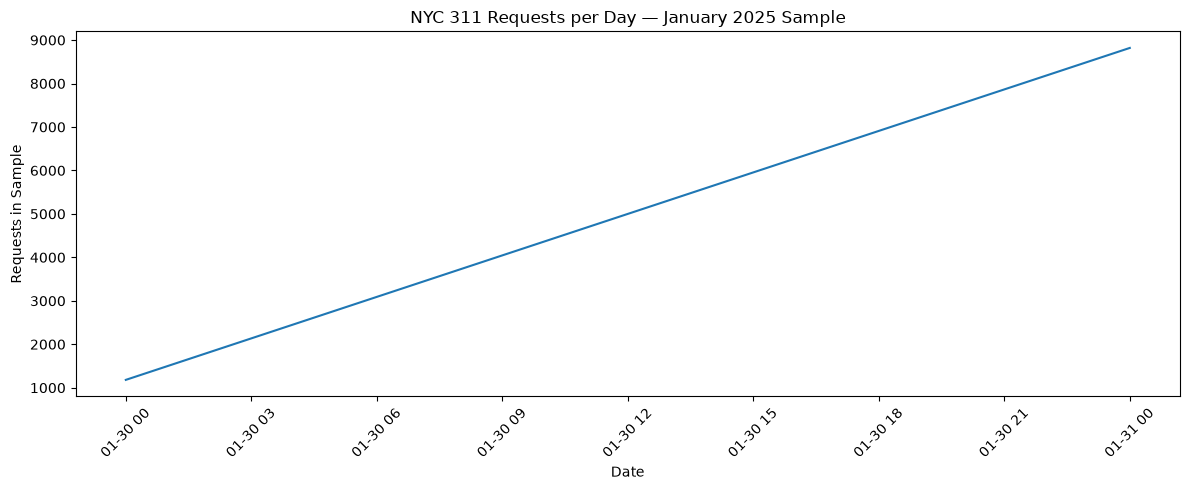

In [22]:
daily_volume = (
    df.dropna(subset=["created_date"])
      .assign(date=lambda x: x["created_date"].dt.date)
      .groupby("date")
      .size()
      .rename("request_count")
      .reset_index()
)

display(daily_volume.head())
display(daily_volume.describe())

plt.figure(figsize=(12, 5))
plt.plot(daily_volume["date"], daily_volume["request_count"])
plt.title("NYC 311 Requests per Day — January 2025 Sample")
plt.xlabel("Date")
plt.ylabel("Requests in Sample")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

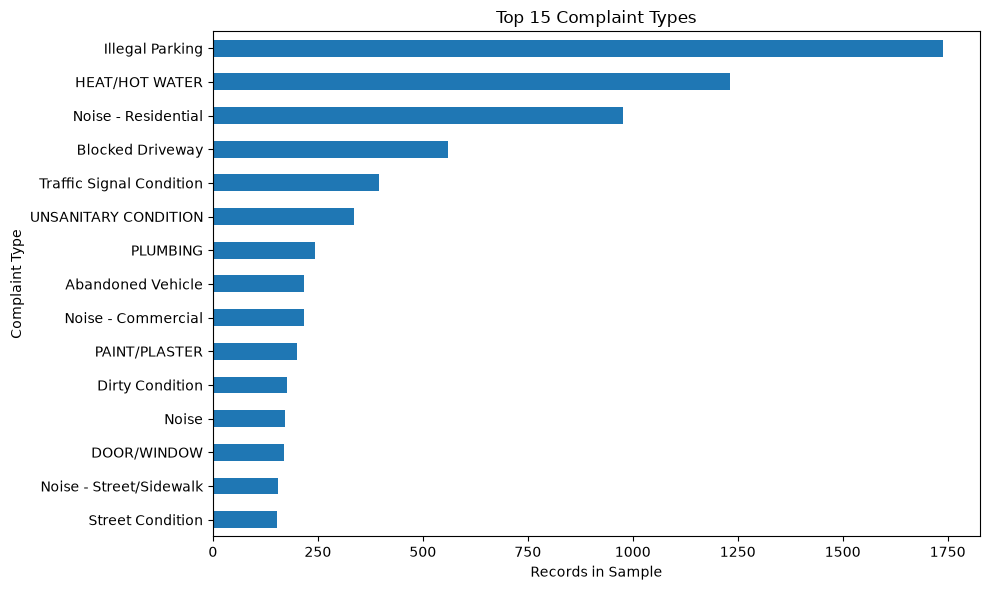

In [23]:
top_complaints = df["complaint_type"].value_counts().head(15)

plt.figure(figsize=(10, 6))
top_complaints.sort_values().plot(kind="barh")
plt.title("Top 15 Complaint Types")
plt.xlabel("Records in Sample")
plt.ylabel("Complaint Type")
plt.tight_layout()
plt.show()

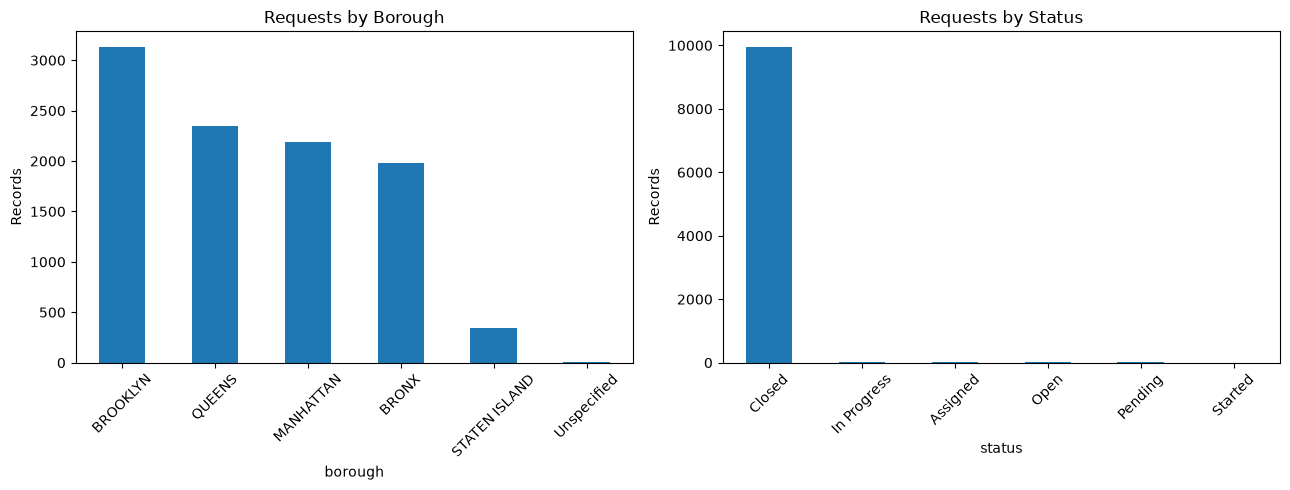

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df["borough"].fillna("Missing").value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Requests by Borough")
axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=45)

df["status"].fillna("Missing").value_counts().head(10).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Requests by Status")
axes[1].set_ylabel("Records")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Valid resolution-time records: 9930


,resolution_hours
count,9930.000000
mean,247.404314
std,863.041473
min,0.000000
25%,1.431458
50%,8.934167
75%,81.559792
95%,1432.168528
max,14431.645278


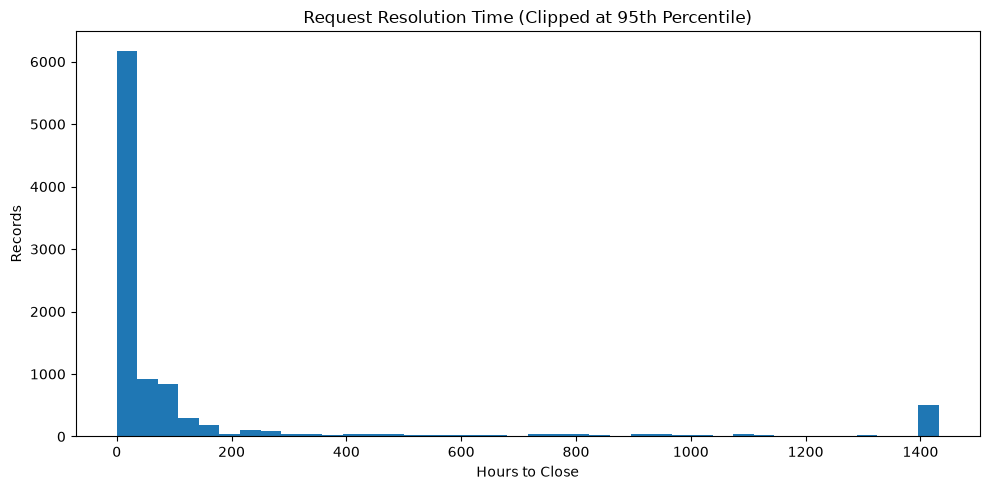

In [25]:
# Calculate elapsed time for requests with valid creation and closing dates
df["resolution_hours"] = (
    df["closed_date"] - df["created_date"]
).dt.total_seconds() / 3600

valid_resolution = df.loc[
    df["resolution_hours"].ge(0), "resolution_hours"
]

print("Valid resolution-time records:", len(valid_resolution))
display(valid_resolution.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).to_frame())

plt.figure(figsize=(10, 5))
valid_resolution.clip(upper=valid_resolution.quantile(0.95)).plot(
    kind="hist", bins=40
)
plt.title("Request Resolution Time (Clipped at 95th Percentile)")
plt.xlabel("Hours to Close")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

In [26]:
quality_summary = pd.DataFrame({
    "metric": [
        "total_rows",
        "total_columns",
        "missing_cells",
        "missing_cell_rate_pct",
        "fully_duplicated_rows",
        "duplicate_request_ids",
        "unique_request_ids",
        "invalid_created_dates",
        "invalid_closed_dates",
        "missing_complaint_type",
        "missing_borough",
        "missing_status"
    ],
    "value": [
        len(df),
        df.shape[1],
        int(df.isnull().sum().sum()),
        round(df.isnull().sum().sum() / df.size * 100, 2),
        int(df.duplicated().sum()),
        int(df["unique_key"].duplicated().sum()),
        int(df["unique_key"].nunique()),
        int(df["created_date"].isnull().sum()),
        int(df["closed_date"].isnull().sum()),
        int(df["complaint_type"].isnull().sum()),
        int(df["borough"].isnull().sum()),
        int(df["status"].isnull().sum())
    ]
})

display(quality_summary)

,metric,value
0,total_rows,10000.00
1,total_columns,9.00
2,missing_cells,227.00
3,missing_cell_rate_pct,0.25
4,fully_duplicated_rows,0.00
5,duplicate_request_ids,0.00
6,unique_request_ids,10000.00
7,invalid_created_dates,0.00
8,invalid_closed_dates,66.00
9,missing_complaint_type,0.00


In [27]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

quality_summary.to_csv(output_dir / "eda_quality_summary.csv", index=False)
daily_volume.to_csv(output_dir / "eda_daily_volume.csv", index=False)

print("EDA summaries saved successfully.")

EDA summaries saved successfully.
